# NLP Lab — Experiment 2: POS Tagging Using spaCy


## Common coarse POS categories
| Tag | Meaning | Example |
|---|---|---|
| `NOUN` | Common noun | student, system |
| `PROPN` | Proper noun | India, Python |
| `VERB` | Main verb | run, analyze |
| `AUX` | Auxiliary verb | is, have |
| `ADJ` | Adjective | good, efficient |
| `ADV` | Adverb | quickly, very |
| `PRON` | Pronoun | he, they |
| `DET` | Determiner | the, a |
| `ADP` | Adposition/preposition | in, on |
| `CCONJ` | Coordinating conjunction | and, but |
| `SCONJ` | Subordinating conjunction | because, although |
| `NUM` | Numeral | two, 10 |
| `PART` | Particle | not, to (depending on usage) |
| `INTJ` | Interjection | wow, oh |
| `PUNCT` | Punctuation | ., !, ? |

## 1. Setup and installation

Run the following commands in a terminal, not in a Python cell. 

```bash
python -m pip install spacy pandas matplotlib
python -m spacy download en_core_web_sm
```
install packages into that kernel.

In [25]:
import spacy
import pandas as pd
import matplotlib.pyplot as plt

print("spaCy version:", spacy.__version__)

try:
    nlp = spacy.load("en_core_web_sm")
    print("English model loaded successfully.")
except OSError as exc:
    raise OSError(
        "The model 'en_core_web_sm' is missing. Run "
        "'python -m spacy download en_core_web_sm' in your environment, "
        "then restart the notebook kernel."
    ) from exc

spaCy version: 3.8.16
English model loaded successfully.


## 2. Prepare the input text
The sample text follows the experiment handout.

In [26]:
text = '''
Natural language processing enables computers to analyze human language.
The students are learning NLP, and the researchers are developing efficient
models for processing large collections of documents.
The team will test the system tomorrow.
'''

doc = nlp(text)

print("Text processed successfully.")
print("Number of tokens:", len(doc))

Text processed successfully.
Number of tokens: 43


## 3. Display each token and its coarse POS tag

In [27]:
for token in doc:
    print(f"{token.text:<15} -> {token.pos_}")


               -> SPACE
Natural         -> ADJ
language        -> NOUN
processing      -> NOUN
enables         -> VERB
computers       -> NOUN
to              -> PART
analyze         -> VERB
human           -> ADJ
language        -> NOUN
.               -> PUNCT

               -> SPACE
The             -> DET
students        -> NOUN
are             -> AUX
learning        -> VERB
NLP             -> PROPN
,               -> PUNCT
and             -> CCONJ
the             -> DET
researchers     -> NOUN
are             -> AUX
developing      -> VERB
efficient       -> ADJ

               -> SPACE
models          -> NOUN
for             -> ADP
processing      -> VERB
large           -> ADJ
collections     -> NOUN
of              -> ADP
documents       -> NOUN
.               -> PUNCT

               -> SPACE
The             -> DET
team            -> NOUN
will            -> AUX
test            -> VERB
the             -> DET
system          -> NOUN
tomorrow        -> NOUN
.               -> P

## 4. POS table

In [28]:
pos_table = pd.DataFrame({
    "Token": [token.text for token in doc],
    "POS": [token.pos_ for token in doc],
})
display(pos_table)

,Token,POS
0,\n,SPACE
1,Natural,ADJ
2,language,NOUN
3,processing,NOUN
4,enables,VERB
5,computers,NOUN
6,to,PART
7,analyze,VERB
8,human,ADJ
9,language,NOUN


## 5. Compare coarse POS and detailed tag

In [29]:
detailed_table = pd.DataFrame({
    "Token": [token.text for token in doc],
    "POS": [token.pos_ for token in doc],
    "Tag": [token.tag_ for token in doc],
})
display(detailed_table)

,Token,POS,Tag
0,\n,SPACE,_SP
1,Natural,ADJ,JJ
2,language,NOUN,NN
3,processing,NOUN,NN
4,enables,VERB,VBZ
5,computers,NOUN,NNS
6,to,PART,TO
7,analyze,VERB,VB
8,human,ADJ,JJ
9,language,NOUN,NN


## 6. POS, lemma, and morphology together
The lemma is a token's base form. Morphological information is model-dependent and may be empty for some tokens.

In [30]:
analysis_table = pd.DataFrame({
    "Token": [token.text for token in doc],
    "POS": [token.pos_ for token in doc],
    "Tag": [token.tag_ for token in doc],
    "Lemma": [token.lemma_ for token in doc],
    "Morphology": [str(token.morph) for token in doc],
})
display(analysis_table)

,Token,POS,Tag,Lemma,Morphology
0,\n,SPACE,_SP,\n,
1,Natural,ADJ,JJ,natural,Degree=Pos
2,language,NOUN,NN,language,Number=Sing
3,processing,NOUN,NN,processing,Number=Sing
4,enables,VERB,VBZ,enable,Number=Sing|Person=3|Tense=Pres|VerbForm=Fin
5,computers,NOUN,NNS,computer,Number=Plur
6,to,PART,TO,to,
7,analyze,VERB,VB,analyze,VerbForm=Inf
8,human,ADJ,JJ,human,Degree=Pos
9,language,NOUN,NN,language,Number=Sing


## 7. Analyze alphabetic words only
This excludes punctuation and numeric-only tokens from the word-level frequency analysis.

In [31]:
word_table = pd.DataFrame({
    "Token": [t.text for t in doc if t.is_alpha],
    "POS": [t.pos_ for t in doc if t.is_alpha],
    "Tag": [t.tag_ for t in doc if t.is_alpha],
    "Lemma": [t.lemma_ for t in doc if t.is_alpha],
})
display(word_table)

,Token,POS,Tag,Lemma
0,Natural,ADJ,JJ,natural
1,language,NOUN,NN,language
2,processing,NOUN,NN,processing
3,enables,VERB,VBZ,enable
4,computers,NOUN,NNS,computer
5,to,PART,TO,to
6,analyze,VERB,VB,analyze
7,human,ADJ,JJ,human
8,language,NOUN,NN,language
9,The,DET,DT,the


## 8. Count POS categories

In [32]:
pos_counts = (
    word_table["POS"]
    .value_counts()
    .rename_axis("POS")
    .reset_index(name="Count")
)
display(pos_counts)
print("Most frequent POS category:", pos_counts.iloc[0]["POS"] if not pos_counts.empty else "N/A")

,POS,Count
0,NOUN,12
1,VERB,6
2,ADJ,4
3,DET,4
4,AUX,3
5,ADP,2
6,PART,1
7,PROPN,1
8,CCONJ,1


Most frequent POS category: NOUN


## 9. Visualize POS distribution

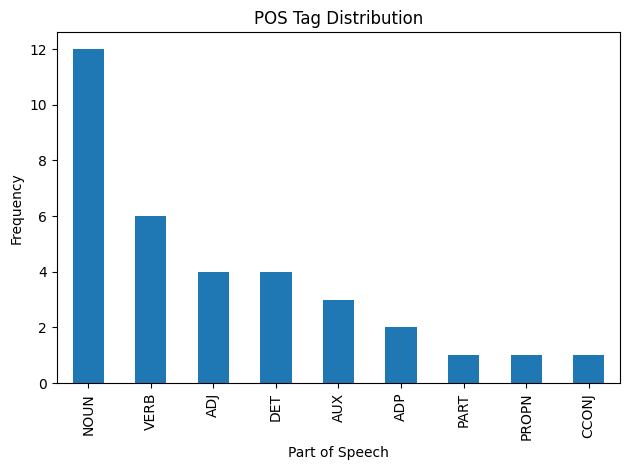

In [33]:
ax = pos_counts.plot(
    kind="bar",
    x="POS",
    y="Count",
    legend=False,
    title="POS Tag Distribution",
)
ax.set_xlabel("Part of Speech")
ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

## 10. Test context-dependent tagging
The same spelling can be assigned different grammatical categories depending on the sentence.

In [34]:
sentences = [
    "I read a book every week.",
    "Please book a ticket for tomorrow.",
    "They watch the match.",
    "They match the colors carefully.",
    "The light is bright.",
    "Please light the lamp.",
]

ambiguous_rows = []
for sentence in sentences:
    sentence_doc = nlp(sentence)
    print("\\nSentence:", sentence)
    for token in sentence_doc:
        if token.text.lower() in {"book", "match", "light"}:
            print(
                f"  {token.text:<10} POS={token.pos_:<8} "
                f"TAG={token.tag_:<8} LEMMA={token.lemma_}"
            )
            ambiguous_rows.append({
                "Sentence": sentence,
                "Token": token.text,
                "POS": token.pos_,
                "Tag": token.tag_,
                "Lemma": token.lemma_,
            })

ambiguous_table = pd.DataFrame(ambiguous_rows)
display(ambiguous_table)

\nSentence: I read a book every week.
  book       POS=NOUN     TAG=NN       LEMMA=book
\nSentence: Please book a ticket for tomorrow.
  book       POS=VERB     TAG=VB       LEMMA=book
\nSentence: They watch the match.
  match      POS=NOUN     TAG=NN       LEMMA=match
\nSentence: They match the colors carefully.
  match      POS=VERB     TAG=VBP      LEMMA=match
\nSentence: The light is bright.
  light      POS=NOUN     TAG=NN       LEMMA=light
\nSentence: Please light the lamp.
  light      POS=VERB     TAG=VB       LEMMA=light


,Sentence,Token,POS,Tag,Lemma
0,I read a book every week.,book,NOUN,NN,book
1,Please book a ticket for tomorrow.,book,VERB,VB,book
2,They watch the match.,match,NOUN,NN,match
3,They match the colors carefully.,match,VERB,VBP,match
4,The light is bright.,light,NOUN,NN,light
5,Please light the lamp.,light,VERB,VB,light


## 11. Final POS analysis table

In [35]:
final_table = pd.DataFrame([
    {
        "Sentence": token.sent.text.strip(),
        "Token": token.text,
        "POS": token.pos_,
        "Tag": token.tag_,
        "Lemma": token.lemma_,
        "Morphology": str(token.morph),
    }
    for token in doc
])
display(final_table)

,Sentence,Token,POS,Tag,Lemma,Morphology
0,Natural language processing enables computers ...,\n,SPACE,_SP,\n,
1,Natural language processing enables computers ...,Natural,ADJ,JJ,natural,Degree=Pos
2,Natural language processing enables computers ...,language,NOUN,NN,language,Number=Sing
3,Natural language processing enables computers ...,processing,NOUN,NN,processing,Number=Sing
4,Natural language processing enables computers ...,enables,VERB,VBZ,enable,Number=Sing|Person=3|Tense=Pres|VerbForm=Fin
5,Natural language processing enables computers ...,computers,NOUN,NNS,computer,Number=Plur
6,Natural language processing enables computers ...,to,PART,TO,to,
7,Natural language processing enables computers ...,analyze,VERB,VB,analyze,VerbForm=Inf
8,Natural language processing enables computers ...,human,ADJ,JJ,human,Degree=Pos
9,Natural language processing enables computers ...,language,NOUN,NN,language,Number=Sing


## 12. Results and interpretation
Run the cells above, then use the generated tables to answer these questions. The exact counts and tags are produced by the installed spaCy model, so they are intentionally not hard-coded.

In [36]:
# Summary by POS category, including examples of tokens
summary = (
    word_table.groupby("POS")
    .agg(
        Frequency=("Token", "size"),
        Example_Tokens=("Token", lambda s: ", ".join(s.head(5))),
    )
    .reset_index()
    .sort_values("Frequency", ascending=False)
)
display(summary)

,POS,Frequency,Example_Tokens
5,NOUN,12,"language, processing, computers, language, stu..."
8,VERB,6,"enables, analyze, learning, developing, proces..."
0,ADJ,4,"Natural, human, efficient, large"
4,DET,4,"The, the, The, the"
2,AUX,3,"are, are, will"
1,ADP,2,"for, of"
3,CCONJ,1,and
6,PART,1,to
7,PROPN,1,NLP
